# 4. 回测：模型说的话靠不靠谱？（Kupiec 和 Christoffersen）

**这一本要回答的问题：** 一个模型每天说"明天 99% 的把握亏损不会超过 X"。过了 16 年（4,030 个交易日），我们怎么判断它说得对不对？

两个检验，各自对应一个很朴素的问题：
1. **Kupiec**：突破的**次数**对不对？
2. **Christoffersen**：突破是不是**扎堆**出现？

所有突破次数都来自仓库已经跑好的滚动回测结果（`reports/`），这里不重新跑模型。

In [1]:
from learn_utils import *
from scipy.stats import chi2
from mre.backtest.coverage_tests import (kupiec_pof, christoffersen_independence,
                                         transition_counts, backtest_summary)

garch_t = load_forecasts("GARCH-t, W=500 (Phase 3 旧主模型)")
fhs = load_forecasts("FHS-GJR, W=1000 (正式模型)")
hist = load_forecasts("Historical, W=500")

N = len(fhs)
for name, fc in [("GARCH-t W=500（Phase 3 旧主模型）", garch_t), ("FHS-GJR W=1000（正式模型）", fhs),
                 ("Historical W=500", hist)]:
    print(f"{name:<34} 99% VaR 突破 {breaches(fc, 0.99).sum():>3} 次")
print(f"\n回测天数 N = {N}，如果 99% VaR 完全准确，期望突破 N x 1% = {N * 0.01:.1f} 次")

GARCH-t W=500（Phase 3 旧主模型）        99% VaR 突破  73 次
FHS-GJR W=1000（正式模型）               99% VaR 突破  47 次
Historical W=500                   99% VaR 突破  54 次

回测天数 N = 4030，如果 99% VaR 完全准确，期望突破 N x 1% = 40.3 次


## 第 1 部分：Kupiec——"抛 4,030 次硬币"

### 直觉

如果 99% VaR 是准确的，那么**每一天**都像抛一枚很不公平的硬币：1% 的概率出"突破"，99% 的概率出"没事"。

抛 4,030 次，平均应该出 40.3 次突破。但就算硬币完全没问题，也不会每次都正好 40 次——可能 35 次，也可能 46 次，这是运气。

所以问题变成：**一个"诚实"的模型，靠运气碰到 73 次（GARCH-t）或 47 次（FHS-GJR）突破的可能性有多大？**

### 用模拟来回答：造 10 万个"诚实的平行世界"

每个平行世界里，模型都是完全准确的（每天突破概率正好 1%），我们数一数每个世界里出了多少次突破。

诚实的世界里，突破 >= 73 次的比例：0.0000%
诚实的世界里，突破 >= 47 次的比例：16.1400%


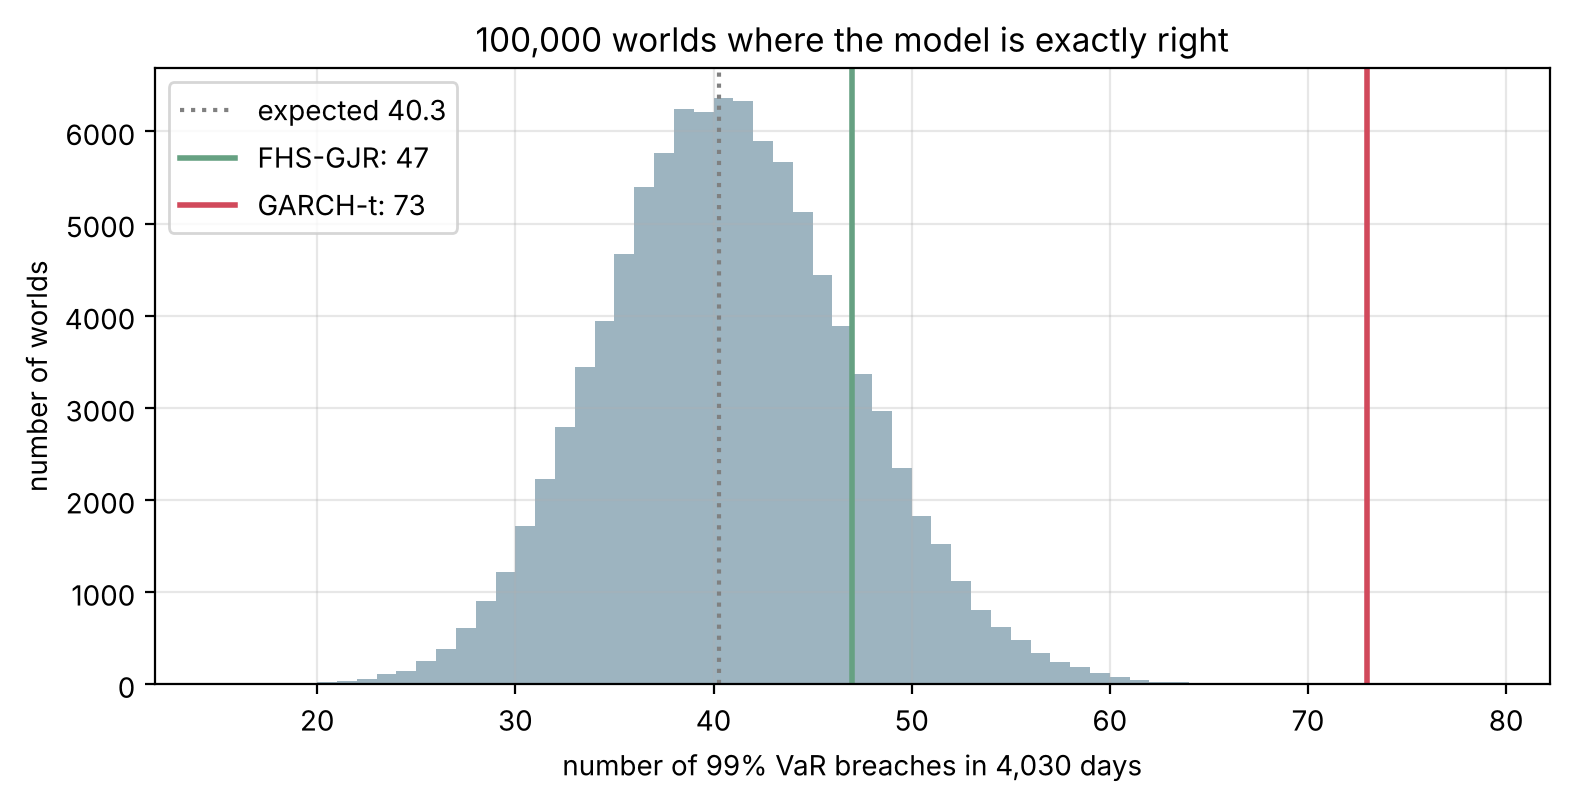

In [2]:
rng = np.random.default_rng(2026)          # 固定随机种子，结果可复现
worlds = rng.binomial(n=N, p=0.01, size=100_000)   # 10 万个世界，每个抛 4030 次 1% 的硬币

for observed in (73, 47):
    share = (worlds >= observed).mean()
    print(f"诚实的世界里，突破 >= {observed} 次的比例：{share:.4%}")

fig, ax = plt.subplots()
ax.hist(worlds, bins=np.arange(15, 80), color="#9db4c0")
ax.axvline(40.3, color="grey", ls=":", label="expected 40.3")
ax.axvline(47, color="#66a182", lw=2, label="FHS-GJR: 47")
ax.axvline(73, color="#d1495b", lw=2, label="GARCH-t: 73")
ax.set_xlabel("number of 99% VaR breaches in 4,030 days"); ax.set_ylabel("number of worlds")
ax.set_title("100,000 worlds where the model is exactly right"); ax.legend(); plt.show()

- **47 次**：在诚实的世界里，碰到 ≥ 47 次的情况并不少见（大约每 6 个世界就有 1 个）。所以 47 **完全可以是运气**，没有理由怀疑 FHS-GJR。
- **73 次**：10 万个诚实的世界里几乎一个都碰不到。"运气不好"解释不了，只能说明 **GARCH-t 系统性地低估了风险**。

### 🎛️ 你来调

`observed` 是观察到的突破次数，`true_p` 是你假设的真实突破概率。试试：
1. 观察到 30 次（比 40.3 少很多），算不算好事？（提示：太少说明 VaR 定得太高、太保守，资本被浪费了，Kupiec 一样会拒绝。）
2. 如果把 `true_p` 设成 1.8%（≈ 73/4030），73 次还奇怪吗？

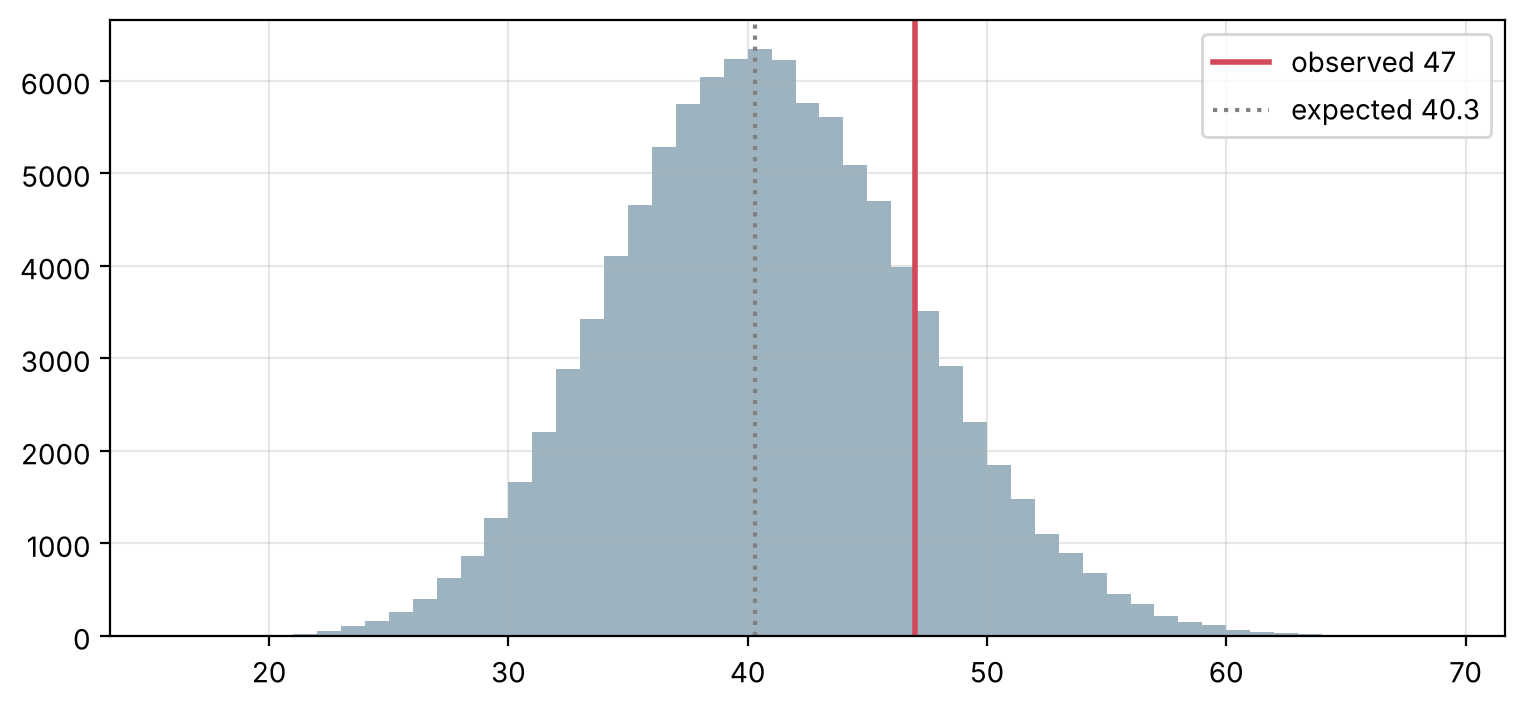

如果真实概率是 1.00%，出现'和 47 次一样离谱或更离谱'的比例 ≈ 0.3024


In [3]:
def coin_lab(observed=47, true_p=0.01, n_days=4030):
    sims = np.random.default_rng(0).binomial(n_days, true_p, size=100_000)
    expected = n_days * true_p
    # "至少这么离谱"：离期望值的距离至少和观察到的一样远（两边都算）
    extreme = (np.abs(sims - expected) >= abs(observed - expected)).mean()
    fig, ax = plt.subplots()
    ax.hist(sims, bins=np.arange(sims.min(), sims.max() + 2), color="#9db4c0")
    ax.axvline(observed, color="#d1495b", lw=2, label=f"observed {observed}")
    ax.axvline(expected, color="grey", ls=":", label=f"expected {expected:.1f}")
    ax.legend(); plt.show()
    print(f"如果真实概率是 {true_p:.2%}，出现'和 {observed} 次一样离谱或更离谱'的比例 ≈ {extreme:.4f}")

coin_lab(47, 0.01)

In [4]:
play(coin_lab, observed=(10, 100, 1), true_p=(0.005, 0.03, 0.001), n_days=[250, 1000, 4030])

（这里是滑块。在 Jupyter 里运行这个单元格就会出现；也可以直接改上面单元格里的数字。）


顺便试试 `n_days = 250`（一年）：一年里期望只有 2.5 次突破，这时 5 次和 2 次都很难分清是运气还是模型问题。**样本越短，检验越没有力量。** 这就是为什么监管的"红绿灯"规则（250 天）只能粗略地看。

### Kupiec 检验：把"模拟"换成一个公式

模拟很直观，但要跑 10 万次。Kupiec 用一个公式直接给出几乎一样的答案。它的想法是比较两种说法哪个更能"解释"我们看到的数据：

- **说法 A（模型说的）**：真实突破率就是 1%。
- **说法 B（数据自己说的）**：真实突破率就是观察到的 突破次数 ÷ 天数（比如 73/4030 = 1.81%）。

说法 B 总是更贴合数据（它就是按数据定的），问题是**贴合多少**。如果 B 比 A 好得多，就拒绝 A，也就是拒绝模型。"好多少"用**似然比 LR** 衡量，LR 越大说明差距越大。LR 大到什么程度算"太大"，查卡方分布（自由度 1）就知道了，查出来的就是 **p 值**。

In [5]:
from scipy.special import xlogy

def log_likelihood(n_breach, n_days, p):
    # "如果真实突破率是 p，看到这个结果有多合理"（取了对数，越大越合理）
    return xlogy(n_days - n_breach, 1 - p) + xlogy(n_breach, p)

for name, fc in [("GARCH-t W=500", garch_t), ("FHS-GJR W=1000", fhs)]:
    h = breaches(fc, 0.99)
    x = int(h.sum())
    llA = log_likelihood(x, N, 0.01)          # 说法 A
    llB = log_likelihood(x, N, x / N)         # 说法 B
    LR = -2 * (llA - llB)
    p_manual = chi2.sf(LR, df=1)
    repo = kupiec_pof(h.values, 0.01)         # 仓库函数
    print(f"{name}: 突破 {x} 次")
    print(f"   说法 A 的对数似然 {llA:9.3f}，说法 B {llB:9.3f}")
    print(f"   LR = {LR:6.3f}，手算 p 值 = {p_manual:.2e}，仓库 kupiec_pof p 值 = {repo.p_value:.2e}")

GARCH-t W=500: 突破 73 次
   说法 A 的对数似然  -375.947，说法 B  -365.142
   LR = 21.609，手算 p 值 = 3.34e-06，仓库 kupiec_pof p 值 = 3.34e-06
FHS-GJR W=1000: 突破 47 次
   说法 A 的对数似然  -256.473，说法 B  -255.939
   LR =  1.068，手算 p 值 = 3.01e-01，仓库 kupiec_pof p 值 = 3.01e-01


- GARCH-t：p 值约 3.3 × 10⁻⁶，远小于 5%，**拒绝**（和 `reports/phase3_report.md` 一致）。
- FHS-GJR：p 值约 0.30，大于 5%，**不拒绝**。

FHS-GJR 的 p 值 0.30，和上面 `coin_lab(47, 0.01)` 用 10 万个平行世界数出来的"一样离谱或更离谱"的比例（约 0.30）几乎一样。公式和"造平行世界"讲的是同一件事，公式只是更快。

## 第 2 部分：Christoffersen——突破是不是"扎堆"？

### 直觉

光次数对还不够。想象两个模型都在 16 年里突破了 40 次：
- 模型甲：40 次**均匀散落**在 16 年里，像随机落下的雨点。
- 模型乙：40 次里有 30 次挤在 2008 年和 2020 年的几个星期里。

模型乙更危险：危机来了它反应太慢，连续好几天都低估风险，而这恰恰是最要命的时候。

一个准确的模型，"昨天突破了"不应该让"今天突破"的概率变大。最简单的检查：**数一数"昨天突破、今天又突破"的情况出现了几次**（仓库报告里叫 `clustered (n11)`）。

最适合拿来说明的是**历史模拟法（W = 500）**：它反应很慢（第 1、2 本讲过），我们来看它的突破是不是扎堆。

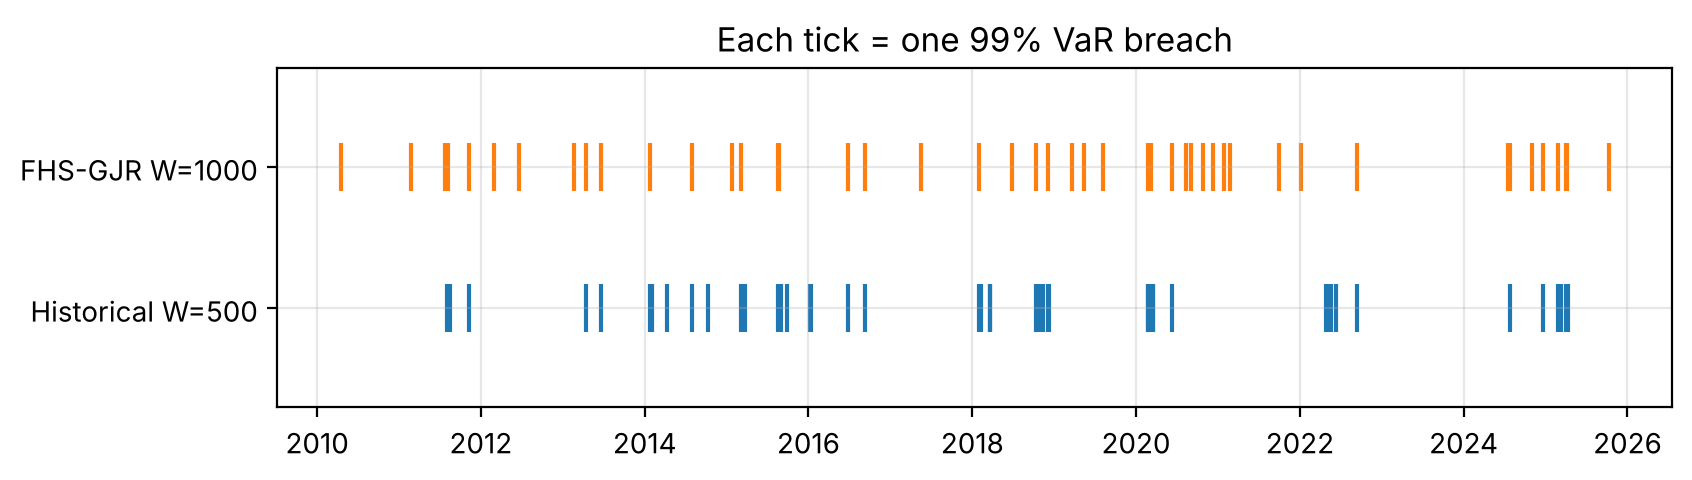

In [6]:
def timeline(fc_dict, alpha=0.99):
    fig, ax = plt.subplots(figsize=(9, 2.2))
    for i, (name, fc) in enumerate(fc_dict.items()):
        h = breaches(fc, alpha).astype(bool)
        ax.scatter(fc.index[h], np.full(h.sum(), i), marker="|", s=300)
    ax.set_yticks(range(len(fc_dict)), list(fc_dict)); ax.set_ylim(-0.7, len(fc_dict) - 0.3)
    ax.set_title(f"Each tick = one {alpha:.0%} VaR breach"); plt.show()

timeline({"Historical W=500": hist, "FHS-GJR W=1000": fhs})

历史模拟的突破（下面一排）在 2011、2015、2018、2020、2022 这些动荡时期挤成一小团一小团；FHS-GJR（上面一排）分布得更均匀一些。下面把"扎堆"数出来：

In [7]:
for name, fc in [("Historical W=500", hist), ("FHS-GJR W=1000", fhs)]:
    h = breaches(fc, 0.99).values
    n00, n01, n10, n11 = transition_counts(h)
    x = h.sum()
    expected_n11 = x * (x / N)          # 如果突破之间互不相关：x 次突破，每次之后第二天再突破的概率约 x/N
    print(f"{name}: 突破 {x} 次；'连续两天都突破' 实际 {n11} 次，如果互不相关大约只会有 {expected_n11:.2f} 次")

Historical W=500: 突破 54 次；'连续两天都突破' 实际 6 次，如果互不相关大约只会有 0.72 次
FHS-GJR W=1000: 突破 47 次；'连续两天都突破' 实际 2 次，如果互不相关大约只会有 0.55 次


历史模拟突破了 54 次，其中"连续两天都突破"出现了 6 次。如果突破是随机散落的，平均只该有 0.7 次左右。

### 再造一次平行世界：把突破的日子随机打乱

为了确认 6 次不是运气，把 54 个突破日在 4,030 天里**随机重新洗牌**（次数不变，只是位置随机），看洗牌后"连续两天都突破"有几次：

In [8]:
h_hist = breaches(hist, 0.99).values
rng = np.random.default_rng(7)
shuffled_n11 = np.array([transition_counts(rng.permutation(h_hist))[3] for _ in range(20_000)])
print(f"洗牌 2 万次，'连续突破' >= 6 次的比例：{(shuffled_n11 >= 6).mean():.4%}")
print(f"洗牌后最常见的次数：{np.bincount(shuffled_n11).argmax()}")

洗牌 2 万次，'连续突破' >= 6 次的比例：0.0100%
洗牌后最常见的次数：0


2 万次洗牌里，几乎没有能达到 6 次的。所以历史模拟的突破**确实扎堆**——它对波动率的变化反应太慢。

### Christoffersen 独立性检验

和 Kupiec 一样，它也是比较两种说法：
- **说法 A（独立）**：不管昨天有没有突破，今天突破的概率都一样。
- **说法 B（有记忆）**："昨天没突破 → 今天突破"的概率，和"昨天突破了 → 今天又突破"的概率可以不一样。

先把 4,030 天两两相邻地数成一张 2×2 的表：

In [9]:
def transition_table(h):
    n00, n01, n10, n11 = transition_counts(h)
    t = pd.DataFrame([[n00, n01], [n10, n11]],
                     index=["昨天没突破", "昨天突破了"], columns=["今天没突破", "今天突破"])
    t["今天突破的比例"] = [f"{n01 / (n00 + n01):.2%}", f"{n11 / (n10 + n11):.2%}"]
    return t

print("Historical W=500, 99% VaR")
display(transition_table(h_hist))
print("FHS-GJR W=1000, 99% VaR")
display(transition_table(breaches(fhs, 0.99).values))

Historical W=500, 99% VaR


,今天没突破,今天突破,今天突破的比例
昨天没突破,3927,48,1.21%
昨天突破了,48,6,11.11%


FHS-GJR W=1000, 99% VaR


,今天没突破,今天突破,今天突破的比例
昨天没突破,3937,45,1.13%
昨天突破了,45,2,4.26%


看最后一列：历史模拟在"昨天突破了"之后，今天再突破的比例（11%）是平时（1.2%）的 9 倍左右。FHS-GJR 这两个比例的差距小得多。把这个差距变成 p 值：

In [10]:
for name, fc in [("Historical W=500", hist), ("FHS-GJR W=1000", fhs), ("GARCH-t W=500", garch_t)]:
    res = christoffersen_independence(breaches(fc, 0.99).values)
    verdict = "拒绝（扎堆）" if res.p_value < 0.05 else "不拒绝"
    print(f"{name:<18} LR = {res.statistic:6.2f}，p 值 = {res.p_value:.2g}  -> 5% 水平下{verdict}")

Historical W=500   LR =  15.92，p 值 = 6.6e-05  -> 5% 水平下拒绝（扎堆）
FHS-GJR W=1000     LR =   2.37，p 值 = 0.12  -> 5% 水平下不拒绝
GARCH-t W=500      LR =   3.70，p 值 = 0.054  -> 5% 水平下不拒绝


历史模拟的 p 值约 6.6 × 10⁻⁵，和 `reports/phase3_report.md` 里一样，强烈拒绝"独立"。

**有意思的对比：** GARCH-t 的次数不对（Kupiec 拒绝），但它的突破不太扎堆（独立性 p 值约 0.054，刚好在 5% 线上方）；历史模拟正好相反——次数还凑合，但扎堆严重。两个检验抓的是不同的毛病，所以要一起用。

**条件覆盖检验（conditional coverage, CC）** 就是把两个问题合在一起问："次数对、而且不扎堆"。仓库的 `christoffersen_cc` 算的就是它。

## 🎛️ 第 3 部分：自己挑模型看体检报告

下面可以从仓库所有存好的模型里挑一个，看它的完整回测结果（全部用仓库的 `backtest_summary` 计算）。

In [11]:
def report_card(model="FHS-GJR, W=1000 (正式模型)", alpha=0.99):
    fc = load_forecasts(model)
    s = backtest_summary(breaches(fc, alpha).values, 1 - alpha)
    ok = lambda p: "通过" if p >= 0.05 else "拒绝"
    print(f"{model}，{alpha:.0%} VaR，{s['n']} 天")
    print(f"  突破 {s['violations']} 次（期望 {s['expected']:.1f}），突破率 {s['violation_rate']:.2%}")
    print(f"  连续两天突破 {s['clustered (n11)']} 次")
    print(f"  Kupiec（次数）         p = {s['kupiec_p']:.3g}  {ok(s['kupiec_p'])}")
    print(f"  Christoffersen（扎堆） p = {s['ind_p']:.3g}  {ok(s['ind_p'])}")
    print(f"  条件覆盖（两者合起来） p = {s['cc_p']:.3g}  {ok(s['cc_p'])}")

report_card()

FHS-GJR, W=1000 (正式模型)，99% VaR，4030 天
  突破 47 次（期望 40.3），突破率 1.17%
  连续两天突破 2 次
  Kupiec（次数）         p = 0.301  通过
  Christoffersen（扎堆） p = 0.124  通过
  条件覆盖（两者合起来） p = 0.179  通过


In [12]:
play(report_card, model=list(FORECASTS), alpha=[0.95, 0.99])

（这里是滑块。在 Jupyter 里运行这个单元格就会出现；也可以直接改上面单元格里的数字。）


In [13]:
# 不用滑块的话，一张表看全部模型
rows = []
for m in FORECASTS:
    for a in (0.95, 0.99):
        s = backtest_summary(breaches(load_forecasts(m), a).values, 1 - a)
        rows.append({"模型": m, "置信水平": f"{a:.0%}", "突破": s["violations"], "期望": round(s["expected"], 1),
                     "连续突破": s["clustered (n11)"], "Kupiec p": round(s["kupiec_p"], 4),
                     "独立性 p": round(s["ind_p"], 4), "CC p": round(s["cc_p"], 4)})
pd.DataFrame(rows)

,模型,置信水平,突破,期望,连续突破,Kupiec p,独立性 p,CC p
0,"FHS-GJR, W=1000 (正式模型)",95%,201,201.5,11,0.9712,0.7499,0.9500
1,"FHS-GJR, W=1000 (正式模型)",99%,47,40.3,2,0.3014,0.1241,0.1794
2,"GJR-skew-t, W=500 (备选)",95%,205,201.5,12,0.8008,0.6163,0.8536
3,"GJR-skew-t, W=500 (备选)",99%,53,40.3,3,0.0551,0.0368,0.0179
4,"GARCH-t, W=500 (Phase 3 旧主模型)",95%,254,201.5,18,0.0003,0.6024,0.0011
5,"GARCH-t, W=500 (Phase 3 旧主模型)",99%,73,40.3,4,0.0000,0.0543,0.0000
6,"Historical, W=500",95%,204,201.5,19,0.8569,0.0100,0.0358
7,"Historical, W=500",99%,54,40.3,6,0.0392,0.0001,0.0000
8,"Normal, W=500",95%,204,201.5,22,0.8569,0.0007,0.0033
9,"Normal, W=500",99%,88,40.3,9,0.0000,0.0001,0.0000


## 最后：公式

| 符号 | 意思 |
|---|---|
| $N$ | 回测天数（4,030） |
| $x$ | 突破次数 |
| $p$ | 模型声称的突破概率（99% VaR 就是 0.01） |
| $\hat p = x/N$ | 观察到的突破率 |
| $n_{ij}$ | 相邻两天里"昨天是 $i$、今天是 $j$"的次数（0 = 没突破，1 = 突破） |
| $\pi_{01} = \dfrac{n_{01}}{n_{00}+n_{01}}$ | 昨天没突破时，今天突破的比例 |
| $\pi_{11} = \dfrac{n_{11}}{n_{10}+n_{11}}$ | 昨天突破了，今天又突破的比例 |

"如果真实概率是 $q$，看到 $x$ 次突破的合理程度"（对数似然）：

$$\log L(q) = (N - x)\log(1-q) + x\log q$$

**Kupiec：** 说法 A 用 $q = p$，说法 B 用 $q = \hat p$

$$LR_{\text{POF}} = -2\big[\log L(p) - \log L(\hat p)\big] \;\sim\; \chi^2(1)$$

**Christoffersen 独立性：** 说法 A 是"一个统一的比例"，说法 B 是"$\pi_{01}$ 和 $\pi_{11}$ 各算各的"

$$LR_{\text{ind}} = -2\big[\log L_{\text{统一比例}} - \log L(\pi_{01}, \pi_{11})\big] \;\sim\; \chi^2(1)$$

**条件覆盖：** 说法 A 是"统一比例而且就等于 $p$"，自由度变成 2。

$\sim \chi^2(1)$ 的意思是"如果模型是对的，LR 大致服从自由度为 1 的卡方分布"，p 值就是"卡方分布里比这个 LR 还大的概率"。

**对应代码：** `src/mre/backtest/coverage_tests.py`，每个检验只有几行，现在应该可以逐行读懂了。

## 小练习

1. 一个 95% VaR 模型回测 4,030 天，期望突破多少次？
2. 某模型 Kupiec 通过、独立性检验拒绝，你会怎么跟面试官描述它的问题？
3. 为什么 FHS-GJR 的 47 次比 40.3 多，我们仍然接受它？

<details><summary>点这里看参考答案</summary>

1. 4,030 × 5% = 201.5 次。FHS-GJR 实际是 201 次。
2. "平均来看突破次数是对的，但突破集中在动荡时期，说明模型对波动率变化反应太慢；危机里会连续多天低估风险。"历史模拟法就是典型例子。
3. 在"模型完全准确"的假设下，靠运气碰到 47 次或更多并不罕见（Kupiec p ≈ 0.30，模拟也显示大约每 6 个世界就有 1 个），所以没有证据说它不准。注意：这是"没有证据说它错"，不等于"证明它对"。
</details>